<a href="https://colab.research.google.com/github/erikh-1126/05-Project-Group/blob/main/05_neural_networks_real_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧪 LAB: Machine Learning to Predict Concrete Compressive Strength

In this lab, you will apply `PyTorch` to a real-world data problem. You will implement a Neural Network in `PyTorch` using the new functionalities introduced this week and compare its performance with a Support Vector Machine and Linear Regression.

Your goal is to predict the **compressive strength of concrete** (the outcome variable, *Y*) based on a set of input features (*X*), including:
**Cement, Blast Furnace Slag, Fly Ash, Water, Superplasticizer, Coarse Aggregate, Fine Aggregate, and Age.**

This dataset and problem are based on the following paper:

- I-Cheng Yeh, "Modeling of strength of high performance concrete using artificial neural networks," Cement and Concrete Research, Vol. 28, No. 12, pp. 1797-1808 (1998). [Link to the paper](yeh1998.pdf).


---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

---
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.

NAME(s) = "Erik H., Henry Y., Derek W."

## 0. Overall Instructions

In this lab, you will work with three models: a **Neural Network**, a **Support Vector Machine (SVM)**, and some form of **Linear Regression**. Each should meet the following requirements:

- **Do not tune the models**. For example, for the Neural Network, choose any number of layers and hidden units you prefer; for the SVM, select a kernel of your choice (e.g., linear, RBF, polynomial), etc.

- **Evaluate model performance using k-fold cross-validation**. That is, run each model using a chosen number of folds (*k*), and report the average performance across all folds. You may select the value of *k* that you want.

- **Be careful with data preprocessing**. Apply all preprocessing steps properly to avoid data leakage (e.g. standardizing features before data splitting)

## 1. Pre-implementation Group Discussion (15 points)

In your group, discuss, agree on, and elaborate the following points:

- **Descriptive analysis**. Identify what exploratory or descriptive analyses you can perform to better understand the relationship between each input variable and the outcome. Consider both visual (e.g., scatter plots, histograms) and statistical summaries.

- **Data preprocessing**. Decide what preprocessing steps are necessary given that you will be using neural networks.

- **Model configuration**. Specify which cost function and output layer activation are most appropriate for your problem type (e.g., regression vs. classification). Explain your reasoning based on the nature of the outcome variable.

- **Performance evaluation**. Describe how you will perform k-fold cross-validation to assess your model’s performance. Include how you will divide the data, compute metrics across folds, and report the final averaged results.

Descriptive analysis: We will make a heat map, scatter plot, and a top coefficients model to better visualize our data. We will also include basic statistics like mean, standard deviation, minimum, maximum, and quartiles for each variable.
Data Preprocessing: We will remove any null values, create a train-holdout set, and scale the training and potentially the holdout set.
Model configuration: cost function is MSE and there is no activation function needed, just one node needed
Model configuration: This will be a regression function with only one node. There won't be an activation function for the last output layer, but there is amongst the hidden layers. The cost function will be MSE, RMSE, and R^2
Performance evaluation: We will use 5-fold cross-validation by randomly dividing the data into five approximately equal groups. In each round, we will train the model on four groups and evaluate it on the remaining group, repeating this until every group has been used for evaluation once.

For each fold, we will fit the scaler only on the training data and use it to transform both the training and validation data to avoid data leakage. We will also initialize and train a fresh model for each fold.

We will calculate MSE, RMSE, and \(R^2\) on each validation fold and report the mean and standard deviation across all five folds. Lower MSE and RMSE indicate smaller prediction errors, while higher \(R^2\) indicates better predictive performance. RMSE is especially useful because it expresses the prediction error in MPa, the same unit as concrete compressive strength.

## 2. Descriptive analysis (10 points)

Apply the descriptive analyses that your group agreed upon in the previous section.

**Load the dataset before beginning the descriptive analysis; you will also use it in the following sections.**

In [1]:
import os
import sys

# Prevent the OpenMP threading conflict found in some macOS installations.
if sys.platform == "darwin":
    os.environ["OMP_NUM_THREADS"] = "1"
    os.environ["OPENBLAS_NUM_THREADS"] = "1"
    os.environ["MKL_NUM_THREADS"] = "1"

import numpy as np
import torch
import torch.nn as nn
from torch import optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, r2_score

# Small networks run efficiently on one CPU thread.
torch.set_num_threads(1)
print("PyTorch:", torch.__version__)


PyTorch: 2.11.0+cpu


Dataset shape: (1030, 9)

Column names:
['Cement (component 1)(kg in a m^3 mixture)', 'Blast Furnace Slag (component 2)(kg in a m^3 mixture)', 'Fly Ash (component 3)(kg in a m^3 mixture)', 'Water  (component 4)(kg in a m^3 mixture)', 'Superplasticizer (component 5)(kg in a m^3 mixture)', 'Coarse Aggregate  (component 6)(kg in a m^3 mixture)', 'Fine Aggregate (component 7)(kg in a m^3 mixture)', 'Age (day)', 'Concrete compressive strength(MPa, megapascals)']

Missing values:
Cement (component 1)(kg in a m^3 mixture)                0
Blast Furnace Slag (component 2)(kg in a m^3 mixture)    0
Fly Ash (component 3)(kg in a m^3 mixture)               0
Water  (component 4)(kg in a m^3 mixture)                0
Superplasticizer (component 5)(kg in a m^3 mixture)      0
Coarse Aggregate  (component 6)(kg in a m^3 mixture)     0
Fine Aggregate (component 7)(kg in a m^3 mixture)        0
Age (day)                                                0
Concrete compressive strength(MPa, megapascals)  

,count,mean,std,min,25%,50%,75%,max
Cement (component 1)(kg in a m^3 mixture),1030.0,281.17,104.51,102.00,192.38,272.90,350.00,540.0
Blast Furnace Slag (component 2)(kg in a m^3 mixture),1030.0,73.90,86.28,0.00,0.00,22.00,142.95,359.4
Fly Ash (component 3)(kg in a m^3 mixture),1030.0,54.19,64.00,0.00,0.00,0.00,118.27,200.1
Water (component 4)(kg in a m^3 mixture),1030.0,181.57,21.36,121.75,164.90,185.00,192.00,247.0
Superplasticizer (component 5)(kg in a m^3 mixture),1030.0,6.20,5.97,0.00,0.00,6.35,10.16,32.2
Coarse Aggregate (component 6)(kg in a m^3 mixture),1030.0,972.92,77.75,801.00,932.00,968.00,1029.40,1145.0
Fine Aggregate (component 7)(kg in a m^3 mixture),1030.0,773.58,80.18,594.00,730.95,779.51,824.00,992.6
Age (day),1030.0,45.66,63.17,1.00,7.00,28.00,56.00,365.0
"Concrete compressive strength(MPa, megapascals)",1030.0,35.82,16.71,2.33,23.71,34.44,46.14,82.6


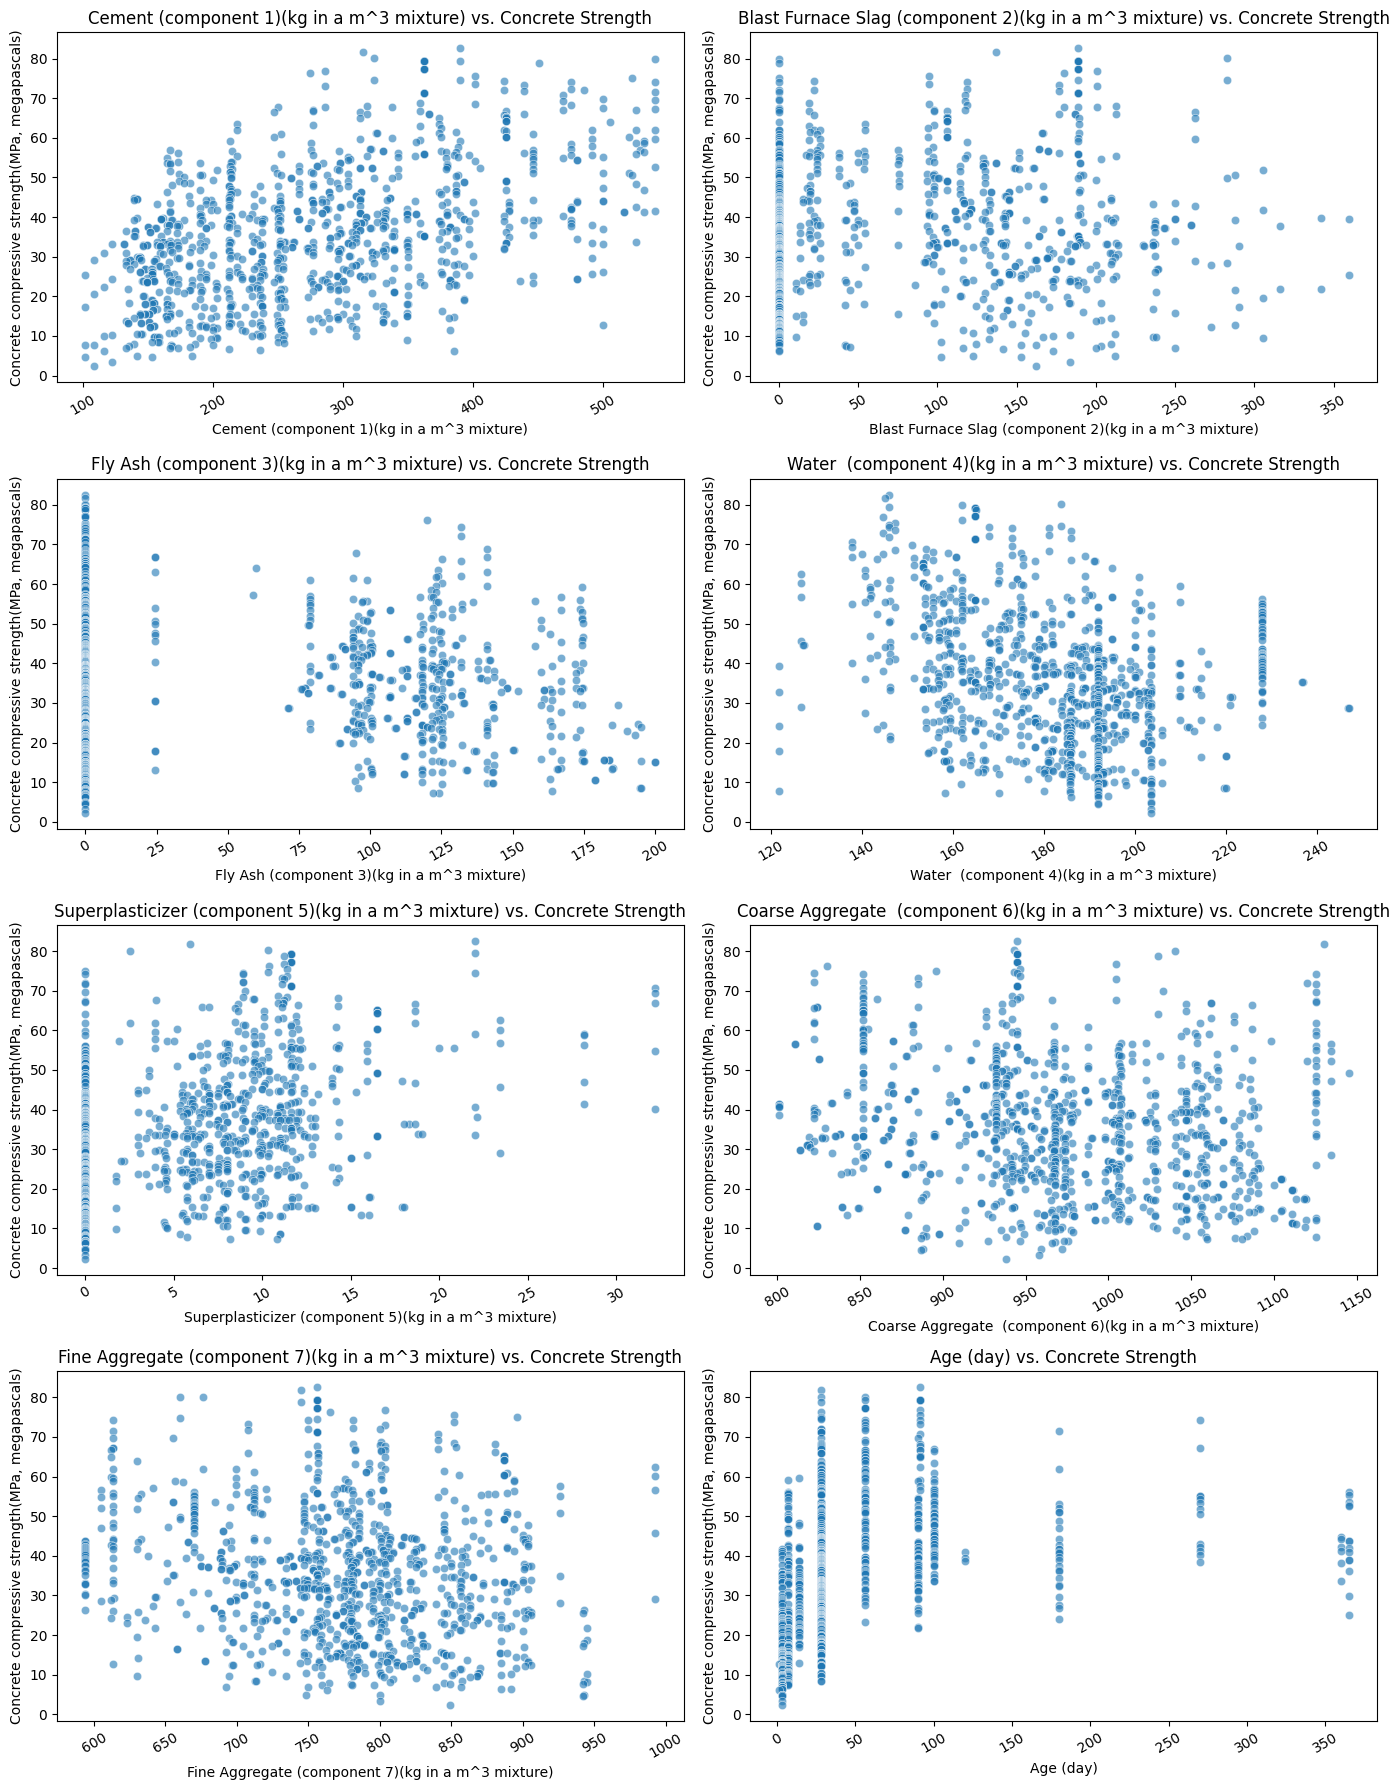

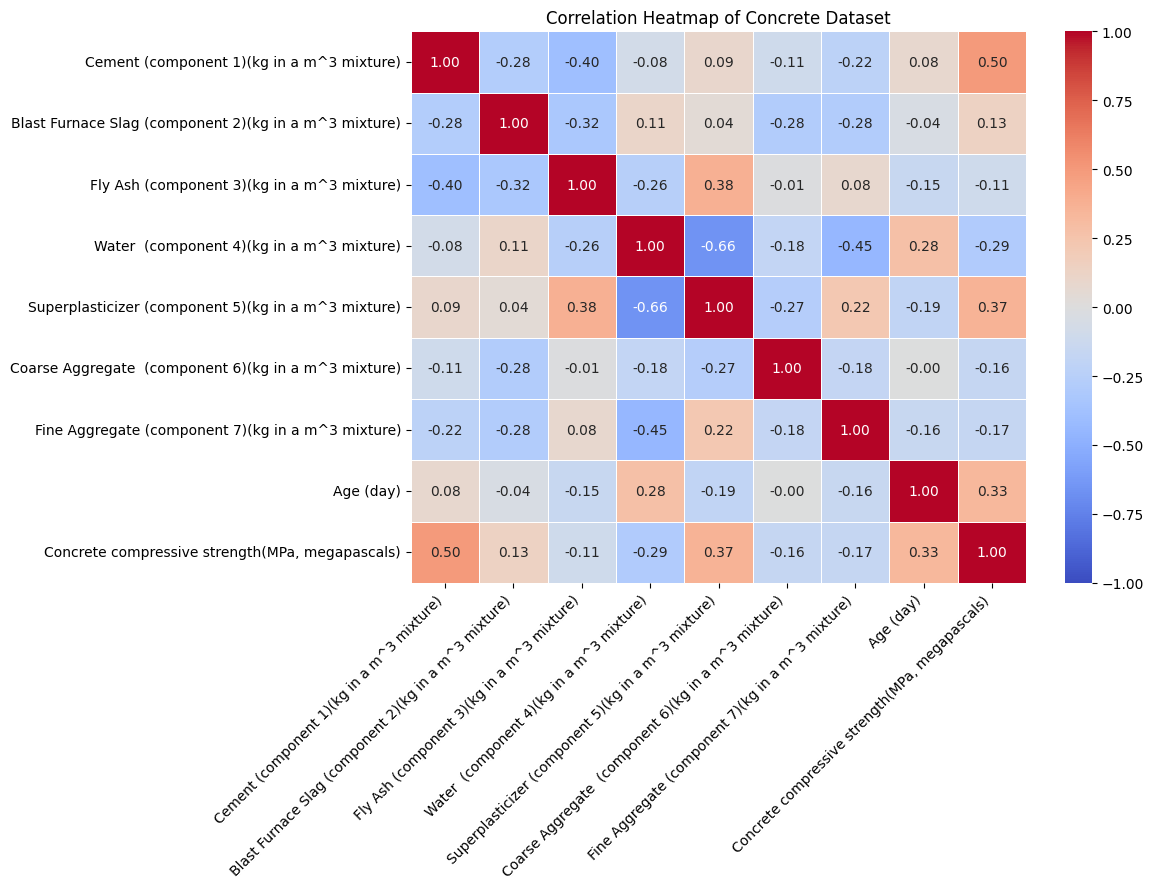

Shape after removing duplicates: (1005, 9)


In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_excel("/content/sample_data/Concrete_Data.xls")

# Clean column names by removing leading/trailing spaces
df.columns = df.columns.str.strip()

# Identify the target variable and input features
target = next(
    col for col in df.columns
    if "compressive strength" in col.lower()
)

features = [col for col in df.columns if col != target]

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

# Check for missing values and duplicate rows
print("\nMissing values:")
print(df.isnull().sum())

print("\nNumber of duplicate rows:", df.duplicated().sum())

# 1. Descriptive statistics
print("\nDescriptive Statistics:")
display(df.describe().T.round(2))

# 2. Scatter plots: each input variable vs. concrete strength
fig, axes = plt.subplots(4, 2, figsize=(14, 18))
axes = axes.flatten()

for i, feature in enumerate(features):
    sns.scatterplot(
        data=df,
        x=feature,
        y=target,
        alpha=0.6,
        ax=axes[i]
    )
    axes[i].set_title(f"{feature} vs. Concrete Strength")
    axes[i].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

# 3. Correlation heatmap
corr = df.corr(numeric_only=True)

plt.figure(figsize=(12, 9))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Concrete Dataset")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# remove exact duplicate rows
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop(columns=[target])
y = df[target]

# Keep raw features here. ConcreteNN fits scalers inside each training fold.
X_train, X_holdout, y_train, y_holdout = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training set:", X_train.shape)
print("Holdout set:", X_holdout.shape)


Training set: (804, 8)
Holdout set: (201, 8)


## 3. Neural Network (40 points)

Implement a neural network as you did in the previous lab, but this time leverage the new functionalities introduced this week. Specifically:

- Your class implementing the neural network should inherit from nn.Module.

- Use `nn.Linear` for the linear transformations between layers, `nn.ReLU` for the hidden-layer activations, and the appropriate activation function for the output layer (e.g., `nn.Sigmoid` for binary classification).

- Use the appropriate cost function from `torch.nn` for your task (e.g., `nn.MSELoss`, `nn.BCELoss`).

- Use Adam from `torch.optim` as the optimizer.

- Use `DataLoader` to efficiently do batch processing. You may choose the batch size freely.

Once you have implemented this class, create an instance of it, then train and evaluate your model on the lab dataset.

**Remember to follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.**

In [5]:
class ConcreteNN(nn.Module):

    def __init__(self, input_dim=8, learning_rate=0.001, batch_size=16):
        super().__init__()
        self.learning_rate = learning_rate
        self.batch_size = batch_size

        # Define the layers, as in the tutorial.
        l1 = nn.Linear(input_dim, 8)
        a1 = nn.ReLU()
        l2 = nn.Linear(8, 8)
        a2 = nn.ReLU()
        l3 = nn.Linear(8, 1)  # No output activation for regression
        l = [l1, a1, l2, a2, l3]
        self.module_list = nn.ModuleList(l)

        # Each model keeps its own scalers.
        self.x_scaler = StandardScaler()
        self.y_scaler = StandardScaler()

    def forward(self, X):
        for f in self.module_list:
            X = f(X)
        return X

    def prepare_data(self, X, y):
        # Fit scalers only on the data passed to fit().
        X_scaled = self.x_scaler.fit_transform(X)
        y_scaled = self.y_scaler.fit_transform(np.asarray(y).reshape(-1, 1))
        X_t = torch.tensor(X_scaled, dtype=torch.float32)
        y_t = torch.tensor(y_scaled, dtype=torch.float32)
        return X_t, y_t

    def fit(self, X, y, n_epochs=200):
        X_t, y_t = self.prepare_data(X, y)
        train_dataset = TensorDataset(X_t, y_t)
        train_loader = DataLoader(
            train_dataset, batch_size=self.batch_size, shuffle=True
        )

        cost_function = nn.MSELoss()
        optimizer = optim.Adam(self.parameters(), lr=self.learning_rate)
        self.train_costs = []

        for epoch in range(n_epochs):
            self.train()
            running_cost = 0.0

            for x_batch, y_batch in train_loader:
                optimizer.zero_grad()               # Clear previous gradients
                y_pred = self(x_batch)               # Forward pass
                cost = cost_function(y_pred, y_batch)
                cost.backward()                     # Calculate gradients
                optimizer.step()                    # Update weights and biases
                running_cost += cost.item() * len(x_batch)

            self.train_costs.append(running_cost / len(train_dataset))

        return self

    def predict(self, X):
        # Reuse the fitted scaler; do not fit it on evaluation data.
        X_t = torch.tensor(self.x_scaler.transform(X), dtype=torch.float32)
        self.eval()
        with torch.no_grad():
            y_pred = self(X_t).numpy()

        # Convert predictions back to MPa.
        return self.y_scaler.inverse_transform(y_pred).ravel()

    def evaluate(self, X, y):
        y_pred = self.predict(X)
        mse = mean_squared_error(y, y_pred)
        return {
            "MSE": mse,
            "RMSE": np.sqrt(mse),
            "R squared": r2_score(y, y_pred)
        }


In [6]:
# Choose these settings once; do not tune them using validation results.
batch_size = 16
n_epochs = 200
learning_rate = 0.001


kf = KFold(n_splits=5, shuffle=True, random_state=42)

X_cv = X_train.to_numpy()
y_cv = y_train.to_numpy()

# Reuse these exact folds for the models in Sections 4 and 5.
cv_splits = list(kf.split(X_cv))
nn_rows = []
nn_histories = []

for fold, (fit_idx, val_idx) in enumerate(cv_splits, start=1):
    # A fresh model fits its own scalers using only the four training folds.
    model = ConcreteNN(
        input_dim=X_cv.shape[1],
        learning_rate=learning_rate,
        batch_size=batch_size
    )
    model.fit(X_cv[fit_idx], y_cv[fit_idx], n_epochs=n_epochs)
    nn_histories.append(model.train_costs)

    # Evaluate on the remaining fold in the original target units.
    metrics = model.evaluate(X_cv[val_idx], y_cv[val_idx])
    nn_rows.append({"Fold": fold, **metrics})
    print(f"Fold {fold}: RMSE = {metrics['RMSE']:.3f} MPa, R squared = {metrics['R squared']:.3f}")

nn_cv_results = pd.DataFrame(nn_rows)
display(nn_cv_results.round(3))

# Report the average and variation across the five folds.
nn_summary = nn_cv_results[["MSE", "RMSE", "R squared"]].agg(["mean", "std"]).T
print("PyTorch neural network, 5-fold CV (mean and standard deviation across folds):")
display(nn_summary.round(3))


Fold 1: RMSE = 6.195 MPa, R squared = 0.834
Fold 2: RMSE = 5.819 MPa, R squared = 0.870
Fold 3: RMSE = 5.836 MPa, R squared = 0.892
Fold 4: RMSE = 6.215 MPa, R squared = 0.854
Fold 5: RMSE = 6.415 MPa, R squared = 0.859


,Fold,MSE,RMSE,R squared
0,1,38.382,6.195,0.834
1,2,33.862,5.819,0.870
2,3,34.064,5.836,0.892
3,4,38.628,6.215,0.854
4,5,41.148,6.415,0.859


PyTorch neural network, 5-fold CV (mean and standard deviation across folds):


,mean,std
MSE,37.217,3.162
RMSE,6.096,0.260
R squared,0.862,0.021


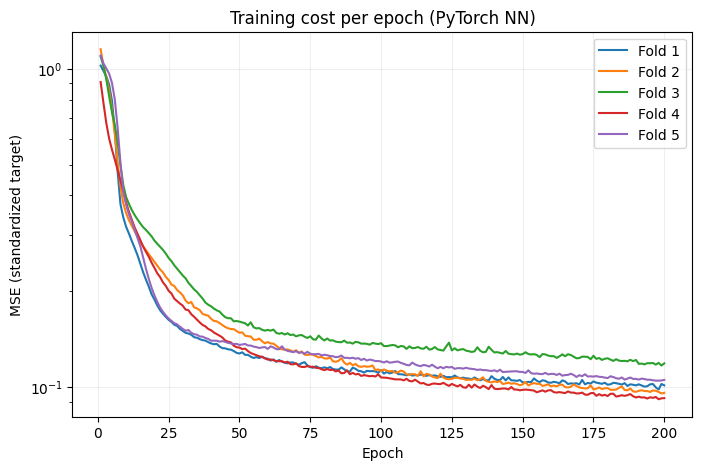

In [7]:

plt.figure(figsize=(8, 5))
for fold, history in enumerate(nn_histories, start=1):
    plt.plot(range(1, n_epochs + 1), history, label=f"Fold {fold}")
plt.title("Training cost per epoch (PyTorch NN)")
plt.xlabel("Epoch")
plt.ylabel("MSE (standardized target)")
plt.yscale("log")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


PyTorch NN holdout: {'MSE': 37.418, 'RMSE': 6.117, 'R squared': 0.838}


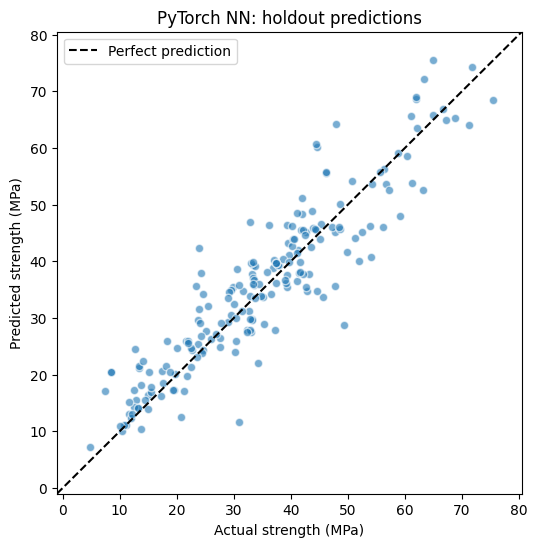

In [8]:
# Train on the full training set, then evaluate once on the holdout set.
final_nn = ConcreteNN(
    input_dim=X_train.shape[1],
    learning_rate=learning_rate,
    batch_size=batch_size
)
final_nn.fit(X_train, y_train, n_epochs=n_epochs)

nn_holdout = final_nn.evaluate(X_holdout, y_holdout)
print("PyTorch NN holdout:", {k: round(float(v), 3) for k, v in nn_holdout.items()})
y_holdout_pred = final_nn.predict(X_holdout)

# Points close to the dashed line have smaller prediction errors.
plt.figure(figsize=(6, 6))
plt.scatter(y_holdout, y_holdout_pred, alpha=0.6, edgecolors="w")
lims = [min(0, y_holdout.min(), y_holdout_pred.min()) - 1,
        max(y_holdout.max(), y_holdout_pred.max()) + 5]
plt.plot(lims, lims, "k--", label="Perfect prediction")
plt.xlim(lims)
plt.ylim(lims)
plt.xlabel("Actual strength (MPa)")
plt.ylabel("Predicted strength (MPa)")
plt.title("PyTorch NN: holdout predictions")
plt.legend()
plt.show()


## 4. Replication (10 points)

Replicate your neural network experiment using the corresponding model class from `scikit-learn`: https://scikit-learn.org/stable/api/sklearn.neural_network.html. Be sure to apply the same neural network architecture as well as the same procedures for model evaluation and preprocessing to ensure a fair comparison.

**Remember**: Follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.

In [14]:
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings("ignore")

sk_rows = []

for fold, (fit_idx, val_idx) in enumerate(cv_splits, start=1):
    X_fit, X_val = X_cv[fit_idx], X_cv[val_idx]
    y_fit, y_val = y_cv[fit_idx], y_cv[val_idx]

    x_scaler = StandardScaler()
    y_scaler = StandardScaler()
    x_fit_scaled = x_scaler.fit_transform(X_fit)
    X_val_scaled = x_scaler.transform(X_val)
    y_fit_scaled = y_scaler.fit_transform(y_fit.reshape(-1, 1)).ravel()

    model = MLPRegressor(
        hidden_layer_sizes=(8, 8),
        activation="relu",
        solver="adam",
        learning_rate_init=learning_rate,
        batch_size=batch_size,
        max_iter=n_epochs,
        alpha=0.0,
        random_state=42
    )
    model.fit(x_fit_scaled, y_fit_scaled)
    y_pred_scaled = model.predict(X_val_scaled)
    y_pred = y_scaler.inverse_transform(y_pred_scaled.reshape(-1, 1)).ravel()

    mse = mean_squared_error(y_val, y_pred)
    r2 = r2_score(y_val, y_pred)
    sk_rows.append({"Fold": fold, "MSE": mse, "RMSE": np.sqrt(mse), "R squared": r2})
    print(f"Fold {fold}: RMSE = {np.sqrt(mse):.3f} MPa, R squared = {r2:.3f}")

sk_cv_results = pd.DataFrame(sk_rows)
display(sk_cv_results.round(3))

print("sklearn MLP, 5-fold CV (mean and standard deviation): ")
display(sk_cv_results[["MSE", "RMSE", "R squared"]].agg(["mean", "std"]).T.round(3))

Fold 1: RMSE = 6.386 MPa, R squared = 0.824
Fold 2: RMSE = 6.124 MPa, R squared = 0.856
Fold 3: RMSE = 6.691 MPa, R squared = 0.858
Fold 4: RMSE = 5.989 MPa, R squared = 0.864
Fold 5: RMSE = 6.081 MPa, R squared = 0.873


,Fold,MSE,RMSE,R squared
0,1,40.778,6.386,0.824
1,2,37.506,6.124,0.856
2,3,44.772,6.691,0.858
3,4,35.864,5.989,0.864
4,5,36.977,6.081,0.873


sklearn MLP, 5-fold CV (mean and standard deviation): 


,mean,std
MSE,39.179,3.622
RMSE,6.254,0.285
R squared,0.855,0.019


In [21]:
x_scaler = StandardScaler()
y_scaler = StandardScaler()
x_train_scaled = x_scaler.fit_transform(X_train)
X_holdout_scaled = x_scaler.transform(X_holdout)
y_train_scaled = y_scaler.fit_transform(y_train.to_numpy().reshape(-1, 1)).ravel()

final_sk = MLPRegressor(
    hidden_layer_sizes=(8, 8),
    activation="relu",
    solver="adam",
    learning_rate_init=learning_rate,
    batch_size=batch_size,
    max_iter=n_epochs,
    alpha=0.0,
    random_state=42)
final_sk.fit(x_train_scaled, y_train_scaled)
sk_pred = y_scaler.inverse_transform(final_sk.predict(X_holdout_scaled).reshape(-1, 1)).ravel()
sk_mse = mean_squared_error(y_holdout, sk_pred)
sk_r2 = r2_score(y_holdout, sk_pred)
print(f"sklearn MLP holdout: MSE = {sk_mse:.3f}, RMSE = {np.sqrt(sk_mse):.3f}, R squared = {sk_r2:.3f}")

sklearn MLP holdout: MSE = 36.447, RMSE = 6.037, R squared = 0.843


## 5. Comparison (20 points)

Apply a Support Vector Machine (SVM) and Linear Regression model to the dataset, and compare their performance with that of your Neural Network.

Discuss any similarities or differences you observe in their results and provide possible explanations for these patterns.

Be sure to apply the k-fold cross-validation procedure to ensure a fair comparison across all models.

**Remember**: Follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.

In [24]:
from sklearn.svm import SVR
from sklearn.linear_model import LinearRegression

svr_rows = []
lr_rows = []

for fold, (fit_idx, val_idx) in enumerate(cv_splits, start=1):
  X_fit, X_val = X_cv[fit_idx], X_cv[val_idx]
  y_fit, y_val = y_cv[fit_idx], y_cv[val_idx]

  x_scaler = StandardScaler()
  y_scaler = StandardScaler()
  X_fit_scaled = x_scaler.fit_transform(X_fit)
  X_val_scaled = x_scaler.transform(X_val)
  y_fit_scaled = y_scaler.fit_transform(y_fit.reshape(-1, 1)).ravel()

  svr = SVR(kernel='rbf')
  svr.fit(X_fit_scaled, y_fit_scaled)
  svr_pred = y_scaler.inverse_transform(svr.predict(X_val_scaled).reshape(-1, 1)).ravel()
  mse = mean_squared_error(y_val, svr_pred)
  r2 = r2_score(y_val, svr_pred)
  svr_rows.append({"Fold": fold, "MSE": mse, "RMSE": np.sqrt(mse), "R squared": r2})

  lr = LinearRegression()
  lr.fit(X_fit_scaled, y_fit_scaled)
  lr_pred = y_scaler.inverse_transform(lr.predict(X_val_scaled).reshape(-1, 1)).ravel()
  mse = mean_squared_error(y_val, lr_pred)
  r2 = r2_score(y_val, lr_pred)
  lr_rows.append({"Fold": fold, "MSE": mse, "RMSE": np.sqrt(mse), "R squared": r2})

  print(f"Fold {fold}: SVR RMSE = {svr_rows[-1]['RMSE']:.3f}, LR RMSE = {lr_rows[-1]['RMSE']:.3f}")

svr_cv_results = pd.DataFrame(svr_rows)
lr_cv_results = pd.DataFrame(lr_rows)

Fold 1: SVR RMSE = 6.894, LR RMSE = 10.672
Fold 2: SVR RMSE = 7.117, LR RMSE = 10.025
Fold 3: SVR RMSE = 7.224, LR RMSE = 10.848
Fold 4: SVR RMSE = 6.718, LR RMSE = 10.578
Fold 5: SVR RMSE = 6.826, LR RMSE = 9.662


In [38]:
comparison = pd.DataFrame({
    "PyTorch NN": nn_cv_results[["MSE", "RMSE", "R squared"]].mean(),
    "sklearn MLP": sk_cv_results[["MSE", "RMSE", "R squared"]].mean(),
    "SVR": svr_cv_results[["MSE", "RMSE", "R squared"]].mean(),
    "Linear Regression": lr_cv_results[["MSE", "RMSE", "R squared"]].mean(),
}).T

comparison["RMSE std"] = [float(r["RMSE"].std()) for r in
                          [nn_cv_results, sk_cv_results, svr_cv_results, lr_cv_results]]

print("5-fold CV comparison, Mean across folds:")
display(comparison.round(3))

5-fold CV comparison, Mean across folds:


,MSE,RMSE,R squared,RMSE std
PyTorch NN,37.217,6.096,0.862,0.260
sklearn MLP,39.179,6.254,0.855,0.285
SVR,48.421,6.956,0.821,0.209
Linear Regression,107.461,10.357,0.601,0.496


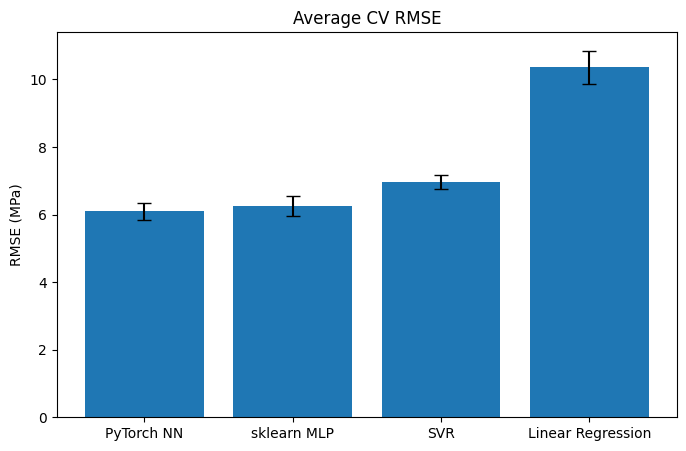

In [37]:
names = ["PyTorch NN", "sklearn MLP", "SVR", "Linear Regression"]
results = [nn_cv_results, sk_cv_results, svr_cv_results, lr_cv_results]

means = [float(r["RMSE"].mean()) for r in results]
stds = [float(r["RMSE"].std()) for r in results]

plt.figure(figsize=(8, 5))
plt.bar(names, means, yerr=stds, capsize=5)
plt.title("Average CV RMSE")
plt.ylabel("RMSE (MPa)")
plt.show()

In [34]:
svr = SVR(kernel='rbf').fit(x_train_scaled, y_train_scaled)
svr_pred = y_scaler.inverse_transform(svr.predict(X_holdout_scaled).reshape(-1, 1)).ravel()

lr = LinearRegression().fit(x_train_scaled, y_train_scaled)
lr_pred = y_scaler.inverse_transform(lr.predict(X_holdout_scaled).reshape(-1, 1)).ravel()

for name, pred in [("SVR", svr_pred), ("Linear Regression", lr_pred)]:
    mse = mean_squared_error(y_holdout, pred)
    r2 = r2_score(y_holdout, pred)
    print(f"{name} holdout: MSE = {mse:.3f}, RMSE = {np.sqrt(mse):.3f}, R squared = {r2:.3f}")

SVR holdout: MSE = 45.008, RMSE = 6.709, R squared = 0.806
Linear Regression holdout: MSE = 109.486, RMSE = 10.464, R squared = 0.527


## 6. Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

The biggest challenge that our group faced was not really being able to collaborate simultaneously on certain questions later down the line. For Question 3, which is by far most heavily weighted and important in the lab, it would be beneficial if we were able to collaborate on it together so we could maximize our knowledge on neural networks on PyTorch. Since we had worked with PyTorch and neural networks, we are certain we would be effective at doing so. Now that in the future, the beginning part of labs are going to be on one computer, we can all work on challenging questions at once.